## Predicting Harvest and Post-Harvest Crop Loss in Nigeria

### 1. Project goal

This project uses main-season data from Nigeria’s National Agricultural Sample Survey 2023 to predict whether a household reported harvest or post-harvest loss for a crop.

Binary classification models will use crop, location, household, and farm characteristics. Logistic regression will serve as the baseline for comparison with tree-based models, evaluated using precision, recall, and F1-score for reported loss.

### 2. Initial data inspection

#### 2.1 Check the working directory and source files

Check that the active Python environment can access the project data. All paths are relative to the project root. The original survey files will remain unchanged.

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

DATA_DIR = Path("data/raw")
HARVEST_FILE = DATA_DIR / "5_Harvest_mainSeason.dta"

print("Working directory:", Path.cwd())

if not HARVEST_FILE.is_file():
  raise FileNotFoundError(
    f"Cannot find {HARVEST_FILE.resolve()}. "
    "Check the working directory and selected kernel"
  )

print("Raw data files:", len(list(DATA_DIR.glob("*.dta"))))

Working directory: /Users/mac/Developer/HIS/Courses/Introduction to Data Science A1N/Assignments/nass-postharvest-project
Raw data files: 21


The project data directory is accessible from the active environment and contains 21 Stata files. I will begin with the main-season harvest file because it contains the reported-loss outcome.

#### 2.2 Load the main-season harvest data

I load the harvest file and inspect its dimensions and first few rows. This establishes the size and basic structure of the starting table.

In [3]:
harvest = pd.read_stata(HARVEST_FILE)

print("Rows:", f"{harvest.shape[0]:,}")
print("Colowns:", harvest.shape[1])

display(harvest.head())

Rows: 334,133
Colowns: 68


,hhid,zone_id,state_id,lga,sector,final_weight,s01b_harvestedCrops__id,s01b_q02,s01b_q03a,s01b_q03c,...,s01b_q19c,s01b_q20,s01b_q21a,s01b_q21c,s01b_q22,s01b_q23,s01b_q24,s01b_q25,s01b_q26,s01b_q27
0,326074.0,1.0,NASARAWA,TOTO,URBAN,43.316891,RICE,No,0.000000,NaN,...,NaN,Yes,158.000,Unshelled (dry),100.0,None (0%),None (0%),None (0%),None (0%),None (0%)
1,342175.0,1.0,PLATEAU,SHENDAM,RURAL,185.124704,RICE,Yes,1896.000000,Unshelled (dry),...,NaN,No,0.000,NaN,None (0%),None (0%),None (0%),None (0%),None (0%),None (0%)
2,274109.0,3.0,KEBBI,BAGUDO,URBAN,153.188059,GUINEA CORN/SORGHUM,Yes,1500.000000,NaN,...,NaN,Yes,510.000,NaN,10.0,70.0,5.0,None (0%),None (0%),15.0
3,347050.0,2.0,TARABA,JALINGO,RURAL,89.243114,BEANS/COWPEA,Yes,795.555556,Unshelled (dry),...,NaN,No,0.000,NaN,None (0%),None (0%),None (0%),None (0%),None (0%),None (0%)
4,545170.0,4.0,ANAMBRA,IDEMILI NORTH,URBAN,390.568099,MELON/EGUSI,Yes,2.110000,Unshelled (fresh),...,NaN,Yes,2.462,Shelled (dry),50.0,None (0%),50.0,None (0%),None (0%),None (0%)


The main-season harvest table contains 334,133 records and 68 variables. The preview shows household identifiers, geographical information, crop
identifiers, and questions about harvest use and losses.

#### 2.3 Inspect the prediction target

The proposed target is `s01b_q11`, which records whether losses occurred during/after harvest, post-harvest activities, transport, or storage.

I check its response categories, missing values, and class distribution to assess whether it is suitable for binary classification.

In [4]:
TARGET = "s01b_q11"

print("Missing target values:", harvest[TARGET].isna().sum())

target_summary = harvest[TARGET].value_counts(dropna=False).to_frame("records")

target_summary["percent"] = (
  target_summary["records"] / len(harvest) * 100
).round(2)

display(target_summary)

Missing target values: 0


,records,percent
s01b_q11,,
No,295686,88.49
Yes,38447,11.51


- The target contains two response categories with no missing values. Loss was reported for 38,447 records (11.51%), while 295,686 records (88.49%) reported no loss.

- The classes are imbalanced. Predicting no loss for every record would achieve 88.49% accuracy while identifying none of the reported losses. Accuracy alone will therefore be insufficient for evaluating the models.

- These percentages describe unweighted crop records in this table; they are not national estimates of the percentage of households experiencing loss.

#### Distribution of reported loss

Compare the numbers of household-crop records reporting loss and no loss to show the class imbalance.

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

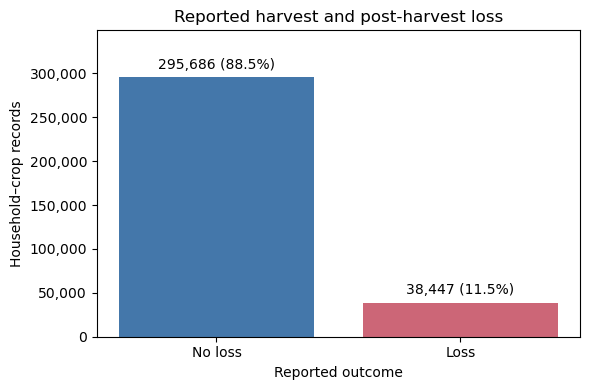

In [6]:
# Count the responses and keep their display order consistent.
loss_counts = (
    harvest["s01b_q11"]
    .value_counts()
    .reindex(["No", "Yes"], fill_value=0)
)

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    ["No loss", "Loss"],
    loss_counts,
    color=["#4477AA", "#CC6677"]
)

# Label each bar with its count and percentage of all harvest records.
labels = [
    f"{count:,} ({count / len(harvest):.1%})"
    for count in loss_counts
]

ax.bar_label(bars, labels=labels, padding=4)

ax.set(
    title="Reported harvest and post-harvest loss",
    xlabel="Reported outcome",
    ylabel="Household–crop records"
)

# Display counts with commas and leave space above the labels.
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, loss_counts.max() * 1.18)

plt.tight_layout()
plt.show()

No-loss records are much more common than loss records. This imbalance explains why a classifier can achieve high accuracy while detecting few or no losses.

#### 2.4 Check the unit of observation

A household may report several crops. I check whether the combination of household ID and harvested-crop ID uniquely identifies each record.

This determines if there are other tables that must be joined and helps establish an appropriate validation strategy.

In [7]:
ROW_KEY = ["hhid", "s01b_harvestedCrops__id"]

print("Distict households:", f"{harvest['hhid'].nunique():,}")

print("\nMissing values in the key:")
display(harvest[ROW_KEY].isna().sum())

print(
  "Duplicate household-crop keys:",
  harvest.duplicated(ROW_KEY).sum()
)

Distict households: 116,406

Missing values in the key:


hhid                       0
s01b_harvestedCrops__id    0
dtype: int64

Duplicate household-crop keys: 0


- The table contains 116,406 distinct households. None of the key columns has missing values, and no household-crop key combinations are duplicated.

- A row can therefore be treated as one household-crop record within the main-season harvest table. Multiple records can belong to the same household.

- Other data must be made compatible before joining. During model validation, all records from a household will be kept in the same partition to prevent household overlap between training and testing.

#### 2.5 Understand the variables and identify candidate predictors

Before selecting predictors, I inspect the descriptions stored in the Stata file. This helps distinguish potential predictors from the target, household identifiers, survey weights, and information that reveals losses.

Candidate predictors should describe information available before harvest, consistent with the intended prediction point.

In [8]:
# Open the stata file to access its metadata, including variable descriptions.
with pd.read_stata(HARVEST_FILE, iterator=True) as reader:
  variable_labels = reader.variable_labels()

# Convert the descriptions into a table.
variable_dictionary = pd.DataFrame({
  "description": variable_labels
})

# Give the table's row index a meaningful label.
variable_dictionary.index.name = "variable"

#Inspect examples of different variable roles:
# identifiers, potential predictors, sampling information, and loss outcomes.
columns_to_inspect = [
  "hhid",
  "zone_id",
  "state_id",
  "sector",
  "final_weight",
  "s01b_harvestedCrops__id",
  TARGET,
  "s01b_q12a"
]

# Select and display the descriptions for these variables.
display(variable_dictionary.loc[columns_to_inspect])

,description
variable,
hhid,HOUSEHOLD ID
zone_id,Zone
state_id,STATE
sector,sector
final_weight,Sampling HH weight
s01b_harvestedCrops__id,Id in s01b_harvestedCrops
s01b_q11,"Were there losses during/after harvest, during..."
s01b_q12a,Harvested quantity lost during the harvest (i...


In [9]:
candidate_predictors = [
  "zone_id",
  "state_id",
  "sector",
  "s01b_harvestedCrops__id"
]

display(harvest[candidate_predictors].head(10))
display(harvest[candidate_predictors].dtypes)

,zone_id,state_id,sector,s01b_harvestedCrops__id
0,1.0,NASARAWA,URBAN,RICE
1,1.0,PLATEAU,RURAL,RICE
2,3.0,KEBBI,URBAN,GUINEA CORN/SORGHUM
3,2.0,TARABA,RURAL,BEANS/COWPEA
4,4.0,ANAMBRA,URBAN,MELON/EGUSI
5,3.0,KEBBI,RURAL,GROUND NUT/PEANUTS
6,5.0,RIVERS,RURAL,MAIZE
7,6.0,OGUN,URBAN,MAIZE
8,1.0,NASARAWA,RURAL,BEENI-SEED/SESAME
9,2.0,BAUCHI,RURAL,GROUND NUT/PEANUTS


zone_id                     float64
state_id                   category
sector                     category
s01b_harvestedCrops__id    category
dtype: object

- Crop category, geographical zone, state, and urban/rural sector are initial candidate predictors. These describe crop and location information that could be available before harvest.

- The household identifier will be used for joining tables and grouping records during validation, and not as a predictor. The sampling weight will be kept separately for consideration in weighted analysis.

- Loss quantities will be excluded from predictors because they reveal information about the outcome. Although zone is stored numerically, it represents a category and must be treated accordingly.

#### 2.6 Check candidate predictor quality and category frequencies

Check the candidate predictors for missing values and count their distinct values. I then examine category frequencies to identify common and rare categories.


In [10]:
# Run same frequency check for each candidate predictor
for column in candidate_predictors:

  # Count each value, including missing values if present
  counts = harvest[column].value_counts(dropna=False)

  # Strata categorical columns may include predefined labels with no records
  # show only values that actually occur in this table
  counts = counts[counts > 0]
  
  # Turn the counts into a table with a clearly named column
  frequency_table = counts.to_frame("records")

  # Calculate each category's share of all harvest records
  frequency_table["percent"] = (
    frequency_table["records"] / len(harvest) * 100
  ).round(2)

  print(f"\nVariable: {column}")
  display(frequency_table)




Variable: zone_id


,records,percent
zone_id,,
3.0,103771,31.06
1.0,82251,24.62
2.0,70217,21.01
4.0,34798,10.41
5.0,22414,6.71
6.0,20682,6.19



Variable: state_id


,records,percent
state_id,,
KANO,25416,7.61
BAUCHI,20507,6.14
KADUNA,18671,5.59
BENUE,18241,5.46
NIGER,15696,4.70
PLATEAU,15162,4.54
TARABA,13716,4.10
SOKOTO,12537,3.75
JIGAWA,12500,3.74



Variable: sector


,records,percent
sector,,
RURAL,222498,66.59
URBAN,111635,33.41



Variable: s01b_harvestedCrops__id


,records,percent
s01b_harvestedCrops__id,,
MAIZE,71877,21.51
GUINEA CORN/SORGHUM,40492,12.12
BEANS/COWPEA,34206,10.24
RICE,30078,9.00
MILLET/MAIWA,29562,8.85
GROUND NUT/PEANUTS,24527,7.34
WHITE YAM,23664,7.08
SOYA BEANS,11665,3.49
OKRO,8431,2.52


- The four candidate predictors have no missing values. They contain six zones, 37 state/FCT categories, two sectors, and 43 observed crop categories.

- The records are unevenly distributed across categories. Maize has 71,877 records, while tobacco has only nine. Predictions and performance estimates for very rare crops may therefore be less reliable.

#### Most common crops

I examine the ten most frequently represented crops to understand which crop categories contribute most records to the harvest table.

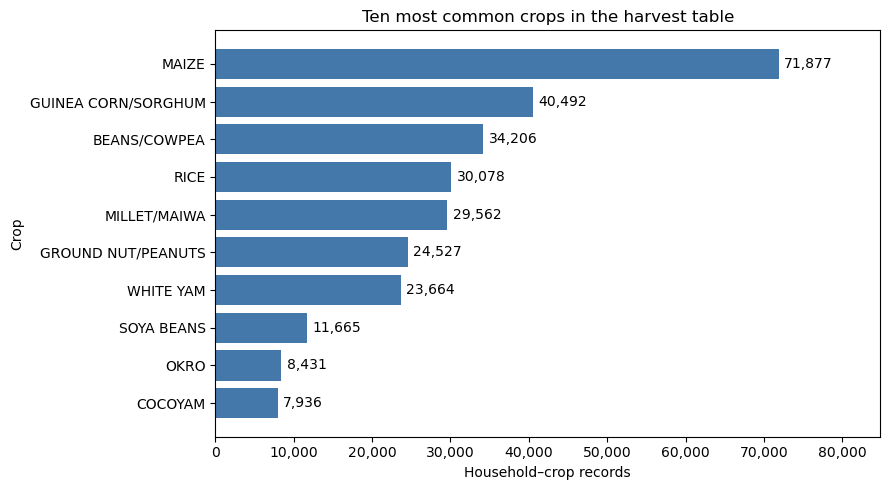

In [13]:
# Select the ten most common crops.
# Sort ascending so the largest bar appears at the top of a horizontal chart.
crop_counts = (
    harvest["s01b_harvestedCrops__id"]
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 5))

# Horizontal bars provide more room for long crop names.
bars = ax.barh(
    crop_counts.index.astype(str),
    crop_counts,
    color="#4477AA"
)

ax.bar_label(
    bars,
    labels=[f"{count:,}" for count in crop_counts],
    padding=4
)

ax.set(
    title="Ten most common crops in the harvest table",
    xlabel="Household–crop records",
    ylabel="Crop"
)

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, crop_counts.max() * 1.18)

plt.tight_layout()
plt.show()

Crop categories are unevenly represented. Overall model scores may therefore hide differences in performance between common and less common crops. This chart shows the ten most common categories, not all crops.

#### 2.7 Inspect additional household, plot, and crop information

Extend the initial predictor set by inspecting a small selection of household and farm characteristics.

The selected variables describe record-keeping, number of cultivated plots,land tenure, irrigation, and planted area. I load their identifiers alongside them so that I can understand how the tables can be connected.

In [11]:
# Household-level information: one record per household.
# Keep the household ID so these characteristics can later be joined.
household_columns = [
  "hhid", # household ID
  "s0dq1",  # Whether the farm keeps transaction records
  "prefilled_plots"  # Number of cultivated plots recorded during listing
]

households = pd.read_stata(
  DATA_DIR / "1_households.dta",
  columns=household_columns
)

# Plot-level information: a household can have several plots.
# A plot is identified by its household ID together with its plot ID
plot_columns = [
  "hhid",
  "s02_plotRoster__id", # Plot ID
  "s02_q04",  # Land tenure arrangement
  "s02_q07"  # Presence of irrigation infrastructure
]

plots = pd.read_stata(
  DATA_DIR / "3_Plot_mainSeason.dta",
  columns=plot_columns
)

# Crop-level information: a household can grow a crop on several plots.
# Keep both plot and crop identifiers to preserve that structure.
crop_columns = [
  "hhid",
  "s02_plotRoster__id",
  "s03_cropRoster__id", # Crop ID
  "planted_area", # Planted area in square metres
  "s03_q05"  # Whether the crop was irrigated
]

crops = pd.read_stata(
  DATA_DIR / "4_Crop_mainSeason.dta",
  columns=crop_columns
)

# Preview the selected fields.
print("Household information:")
display(households.head())

print("Plot information:")
display(plots.head())

print("Crop information:")
display(crops.head())

Household information:


,hhid,s0dq1,prefilled_plots
0,326074.0,PARTIALLY,3.0
1,342175.0,"NO, NEVER",5.0
2,274109.0,OCCASIONALLY,2.0
3,347050.0,"NO, NEVER",2.0
4,545170.0,"NO, NEVER",5.0


Plot information:


,hhid,s02_plotRoster__id,s02_q04,s02_q07
0,326074.0,3.0,Owned by a member of the HH,NO
1,326074.0,1.0,Owned by a member of the HH,NO
2,326074.0,2.0,Owned by a member of the HH,NO
3,342175.0,1.0,Rented from somebody else (out of the HH),NO
4,274109.0,1.0,Owned by a member of the HH,NO


Crop information:


,hhid,s02_plotRoster__id,s03_cropRoster__id,planted_area,s03_q05
0,326074.0,1.0,MAIZE,1123.600000,NaN
1,326074.0,2.0,RICE,2354.900000,NaN
2,326074.0,3.0,GUINEA CORN/SORGHUM,1125.900000,NaN
3,342175.0,1.0,RICE,11235.000000,NaN
4,274109.0,1.0,GUINEA CORN/SORGHUM,10373.999784,NaN


#### 2.8 Check missing values and source-table keys

Check the selected fields for missing values and verify whether the proposed identifiers uniquely identify records in each source table.

These checks help determine which predictors are usable and whether tables must be aggregated before joining.

In [12]:
# Associate a readable table name with each loaded DataFrame.
source_tables = {
  "Households": households,
  "Plots": plots,
  "Crops": crops
}

# Define the columns that should uniquely identify a row in each table.
source_keys = {
  "Households": ["hhid"],
  "Plots": ["hhid", "s02_plotRoster__id"],
  "Crops": ["hhid", "s02_plotRoster__id", "s03_cropRoster__id"]
}

# Check each table using the same procedure.
# .items() provides both its name and its DataFrame on each iteration.
for name, table in source_tables.items():
  print(f"\n{name}: {len(table):,} rows")

  # Count missing values separately for every selected column.
  missing_summary = table.isna().sum().to_frame("missing_records")

  # Use this source table's row count as the percentage denominator.
  missing_summary["missing_percent"] = (
    missing_summary["missing_records"] / len(table) * 100
  ).round(2)

  display(missing_summary)

  # Retrieve the appropriate identifying columns for this table.
  keys = source_keys[name]

  # Count records missing at least one part of their identifying key.
  missing_key_rows = table[keys].isna().any(axis=1).sum()

  print("Rows with an incomplete key:", missing_key_rows)

  # Count repeated combinations of the identifying columns.
  print("Duplicate keys:", table.duplicated(keys).sum())


Households: 143,105 rows


,missing_records,missing_percent
hhid,0,0.00
s0dq1,0,0.00
prefilled_plots,10185,7.12


Rows with an incomplete key: 0
Duplicate keys: 0

Plots: 273,887 rows


,missing_records,missing_percent
hhid,0,0.0
s02_plotRoster__id,0,0.0
s02_q04,0,0.0
s02_q07,0,0.0


Rows with an incomplete key: 0
Duplicate keys: 0

Crops: 480,393 rows


,missing_records,missing_percent
hhid,0,0.00
s02_plotRoster__id,0,0.00
s03_cropRoster__id,0,0.00
planted_area,0,0.00
s03_q05,462760,96.33


Rows with an incomplete key: 0
Duplicate keys: 0


The three source tables have complete, unique identifying keys.

The household plot-count variable has 7.12% missing values. It remains a candidate, but missing values must be handled explicitly.

The crop-level irrigation question has 96.33% missing values. I will exclude it from the initial predictor set.

Plot-level irrigation infrastructure has no missing values and remains a candidate. It measures the presence of infrastructure, which is different from whether a particular crop was actually irrigated.

Household characteristics can be joined through household ID. Plot characteristics must first be connected to crop records using household and plot IDs. The resulting information must then be aggregated to match the household–crop structure of the harvest table.